# Experiment 2: Stability, correctness and class-specific responses
## All 3,421 test images; seed 42; three noise realizations; run-1 ResNet18 224, ResNet50 28 and original ViT

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

seed, batch_size = 42, 32
torch.manual_seed(seed)
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
output = Path('predictions/stability.npz')
output.parent.mkdir(exist_ok=True)
print(device)
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))

cuda


## Ten non-identity levels per operation — translation in subpixels, noise σ on [0, 1], blur radius in pixels

In [2]:
levels = {
    'rotation': np.linspace(-20, 20, 10),
    'translation': np.linspace(-3, 3, 10),
    'brightness': np.linspace(0.8, 1.2, 10),
    'blur': np.linspace(0.15, 1.5, 10),
    'noise': np.linspace(0.01, 0.1, 10),
    'green_scale': np.linspace(0.9, 1.1, 10),
    'red_scale': np.linspace(0.9, 1.1, 10),
    'blue_scale': np.linspace(0.9, 1.1, 10),
}
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    test_images = data['test_images']
    test_labels = data['test_labels'].ravel()
indices = np.arange(len(test_images))
images, labels = test_images[indices], test_labels[indices]
baseline = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)[indices]
    np.testing.assert_array_equal(rows[:, 0], indices)
    np.testing.assert_array_equal(rows[:, 1], labels)
    baseline.append(rows[:, 3:])
baseline = np.stack(baseline)
base_class = baseline.argmax(-1)
all_correct = (base_class == labels).all(axis=0)
print(f'{len(images)} images; {all_correct.sum()} initially correct for all models')

3421 images; 3191 initially correct for all models


## Transform original 28 × 28 RGB images — shared inputs for all models, gray borders, no wraparound

Noise seeds use the original test index, severity and repeat. The previous subset experiment used subset positions, so the full-population noise realizations follow a new explicit seed protocol.

In [3]:
def transform(images, kind, level, repeat=0):
    result = []
    for i, image in enumerate(images):
        pil = Image.fromarray(image)
        if kind == 'rotation':
            changed = pil.rotate(float(level), resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
        elif kind == 'translation':
            changed = pil.transform(pil.size, Image.Transform.AFFINE, (1, 0, -float(level), 0, 1, 0),
                                    resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
        elif kind == 'brightness':
            changed = ImageEnhance.Brightness(pil).enhance(float(level))
        elif kind == 'blur':
            changed = pil.filter(ImageFilter.GaussianBlur(float(level)))
        elif kind == 'noise':
            key = f'{seed}:{i}:{level}:{repeat}'
            noise_seed = int.from_bytes(hashlib.sha256(key.encode()).digest()[:8], 'little')
            noise = np.random.default_rng(noise_seed).normal(0, level, image.shape)
            changed = np.rint(np.clip(image / 255.0 + noise, 0, 1) * 255).astype(np.uint8)
        else:
            channel = {'red_scale': 0, 'green_scale': 1, 'blue_scale': 2}[kind]
            changed = image.astype(float)
            changed[..., channel] *= level
            changed = np.rint(np.clip(changed, 0, 255)).astype(np.uint8)
        result.append(np.asarray(changed))
    return np.stack(result)

## Load models and predict in batches

In [4]:
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

baseline_logits = [np.load(f'predictions/{name}_test.npz')['logits'][indices] for name in model_names]
gate = np.concatenate([np.flatnonzero(labels == c)[:8] for c in range(8)])
for m in range(len(models)):
    np.testing.assert_allclose(predict(m, images[gate])[0], baseline[m, gate], atol=1e-5, rtol=1e-4)


## Run experiment and save full probabilities and raw logits — model × level × realization × image × class

In [5]:
from numpy.lib.format import open_memmap

files = [*checkpoints[:2], 'models/vit/model.safetensors', 'models/vit/config.json', 'models/vit/preprocessor_config.json']
weight_hashes = [hashlib.sha256(Path(path).read_bytes()).hexdigest() for path in files]
signature = hashlib.sha256(images.tobytes() + labels.tobytes() + baseline.tobytes()
                           + str(weight_hashes).encode() + str(levels).encode() + str(seed).encode() + b'test-index-noise-v2').hexdigest()
if output.exists():
    with np.load(output, allow_pickle=False) as saved:
        assert str(saved['signature']) == signature, 'Saved experiment differs from current inputs.'
    print(f'Using validated full-test cache: {output}')
else:
    cache = Path('outputs/stability_test_v2')
    cache.mkdir(parents=True, exist_ok=True)
    lock = cache / 'signature.txt'
    assert not lock.exists() or lock.read_text() == signature, 'Inputs changed: use a new cache directory.'
    lock.write_text(signature)
    probabilities, logits = {}, {}
    for kind, values in levels.items():
        repeats = 3 if kind == 'noise' else 1
        arrays = []
        for suffix, shape, dtype in [('p', (3, 10, repeats, len(images), 8), 'float32'),
                                      ('logits', (3, 10, repeats, len(images), 8), 'float32'),
                                      ('done', (3, 10, repeats), 'bool')]:
            path = cache / f'{kind}_{suffix}.npy'
            fresh = not path.exists()
            a = open_memmap(path, mode='w+' if fresh else 'r+', dtype=dtype, shape=shape)
            if fresh and dtype == 'bool':
                a[:] = False
                a.flush()
            arrays.append(a)
        p, scores, done = arrays
        for j, level in enumerate(values):
            for repeat in range(repeats):
                if done[:, j, repeat].all():
                    continue
                changed = transform(images, kind, level, repeat)
                for m in range(len(models)):
                    if not done[m, j, repeat]:
                        p[m, j, repeat], scores[m, j, repeat] = predict(m, changed)
                        p.flush()
                        scores.flush()
                        done[m, j, repeat] = True
                        done.flush()
        probabilities[kind], logits[kind] = p, scores
        print(f'{kind}: all {len(images)} test images, {len(values)} levels, {repeats} realizations completed')
    np.savez_compressed(output, **probabilities, baseline=baseline, indices=indices, labels=labels,
                        seed=seed, model_names=model_names, class_names=class_names, signature=signature,
                        checkpoints=checkpoints, weight_hashes=weight_hashes, model_input_resolutions=[224,28,224],
                        baseline_logits=np.stack(baseline_logits), split='test', noise_seed_scope='original test index',
                        axes=['model','level','realization','image','class'], border_fill_rgb=[128]*3, input_shape=[28,28,3],
                        **{f'logits_{kind}': scores for kind, scores in logits.items()},
                        **{f'levels_{kind}': values for kind, values in levels.items()})
    print(output)


Using validated full-test cache: predictions\stability.npz


## Load saved results — average noise realizations within each image, not as independent images

In [6]:
with np.load(output, allow_pickle=False) as saved:
    levels = {kind: saved[f'levels_{kind}'] for kind in levels}
    probabilities = {kind: saved[kind] for kind in levels}
    baseline, indices, labels = saved['baseline'], saved['indices'], saved['labels']
    model_names = saved['model_names'].tolist()
    seed = int(saved['seed'])
images = test_images[indices]
base_class = baseline.argmax(-1)
base_probability = np.take_along_axis(baseline, base_class[..., None], axis=-1)[..., 0]
all_correct = (base_class == labels).all(axis=0)
metrics = {}
for kind, p in probabilities.items():
    predicted = p.argmax(-1)
    target = np.broadcast_to(base_class[:, None, None, :, None], p.shape[:-1] + (1,))
    retained = np.take_along_axis(p, target, axis=-1)[..., 0].mean(axis=2)
    correct = (predicted == labels).mean(axis=2)
    metrics[kind] = {
        'Change in p(original class)': retained - base_probability[:, None, :],
        'Label flip fraction': (predicted != base_class[:, None, None, :]).mean(axis=2),
        'Accuracy (all images)': correct,
        'Correct-label retention (all initially correct)': correct[:, :, all_correct],
        'Correct → wrong': (1 - correct) * (base_class == labels)[:, None, :],
        'Wrong → correct': correct * (base_class != labels)[:, None, :],
    }

## 2A — Stability and correctness: ten points per operation; dashed lines mark unmodified references

In [7]:
from matplotlib.ticker import PercentFormatter

change_limits = (-100, 10)
def plot_stability(kind, values):
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.5), layout='constrained')
    reference = 1 if kind in ('brightness', 'green_scale', 'red_scale', 'blue_scale') else 0
    for ax, title in zip(axes, list(metrics[kind])[:4]):
        is_change = title.startswith('Change')
        for m, name in enumerate(model_names):
            data = metrics[kind][title][m]
            y = data.mean(axis=-1) if data.shape[-1] else np.full(10, np.nan)
            if is_change:
                y = 100 * y
                assert change_limits[0] <= y.min() and y.max() <= change_limits[1], 'Change would be clipped.'
            line, = ax.plot(values, y, 'o-', label=name)
            base = (base_class[m] == labels).mean() if title.startswith('Accuracy') else (1 if title.startswith('Correct-label') else 0)
            ax.axhline(base, color=line.get_color(), ls='--', alpha=0.35)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title='Original-class support: change' if is_change else title, xlabel=kind)
        if is_change:
            ax.set(ylim=change_limits, ylabel='Change (percentage points)')
        else:
            ax.set(ylim=(-0.03, 1.03), yticks=np.linspace(0, 1, 5))
            ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(labels)} · shared correct N={all_correct.sum()} · fixed y-scales')
    plt.show()


Compare original-class support and label flips with accuracy, using identical y-scales across transformations rather than judging independently zoomed curves. The experiment covers 3,421 test images, including 3,191 originally classified correctly by all three models, with probability changes shown in percentage points and rates in percent. These panels separate consistency from correctness while preventing different axis ranges from exaggerating differences in response size.

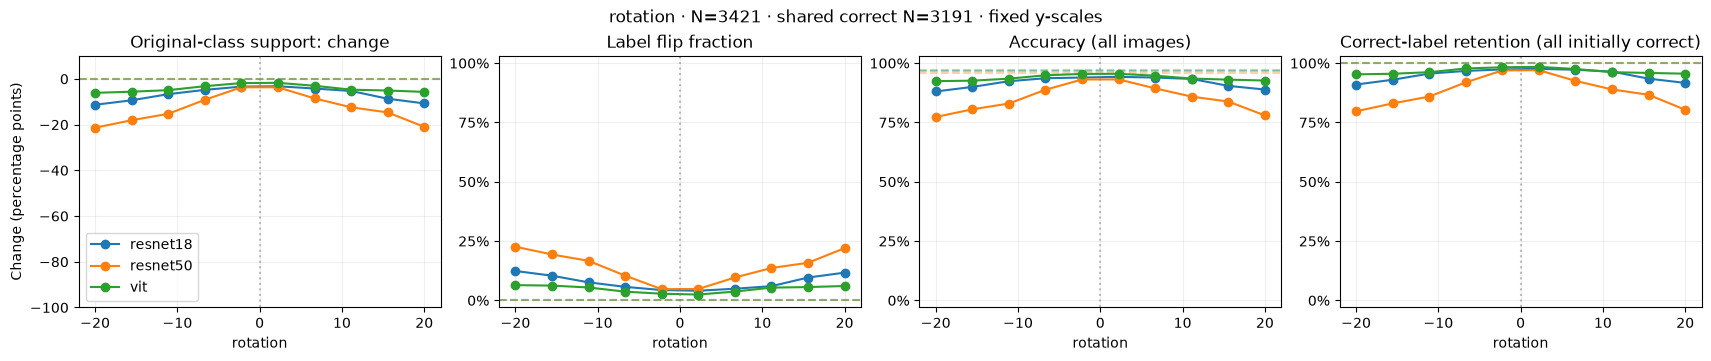

In [8]:
plot_stability('rotation', levels['rotation'])

Compare rotation-induced label flips across models and use the class map below to locate concentrated sensitivity. Rotation changes 14.0% of ResNet50 decisions, versus 7.7% for ResNet18 and 4.8% for ViT, with ResNet50’s basophil original-class support falling by about 0.70. The response is therefore checkpoint- and class-dependent, although rotation includes interpolation and border changes as well as orientation changes.

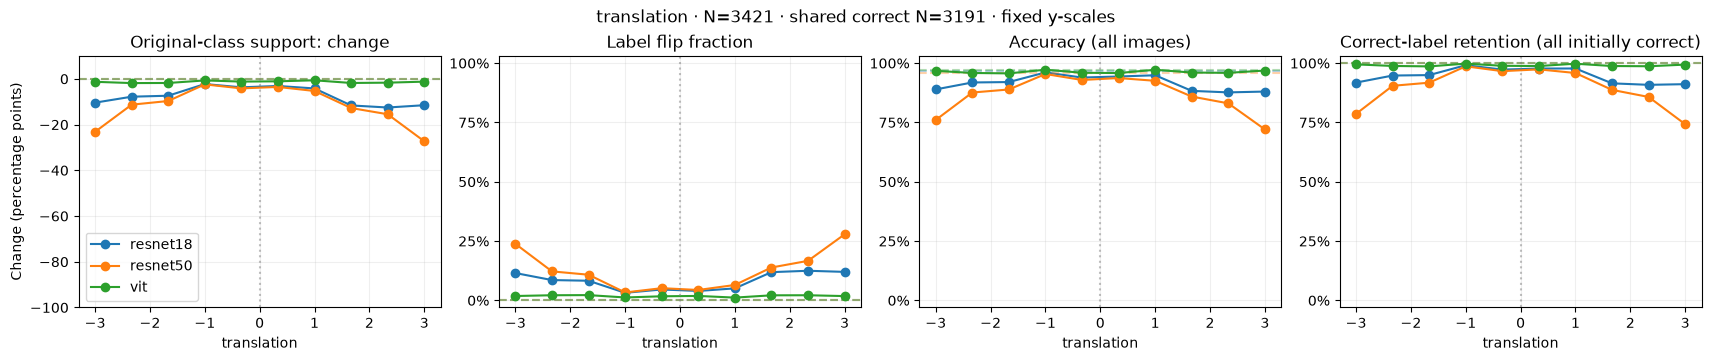

In [9]:
plot_stability('translation', levels['translation'])

Compare both ends of the translation curves rather than judging sensitivity from one shift direction. ResNet50 accuracy falls to 76.0% and 72.1% at the extremes, while ViT remains at 96.8% and 96.9%. ResNet50 is sensitive in both directions, but the non-monotonic individual sequences below show why endpoint-only testing can still miss intermediate failures.

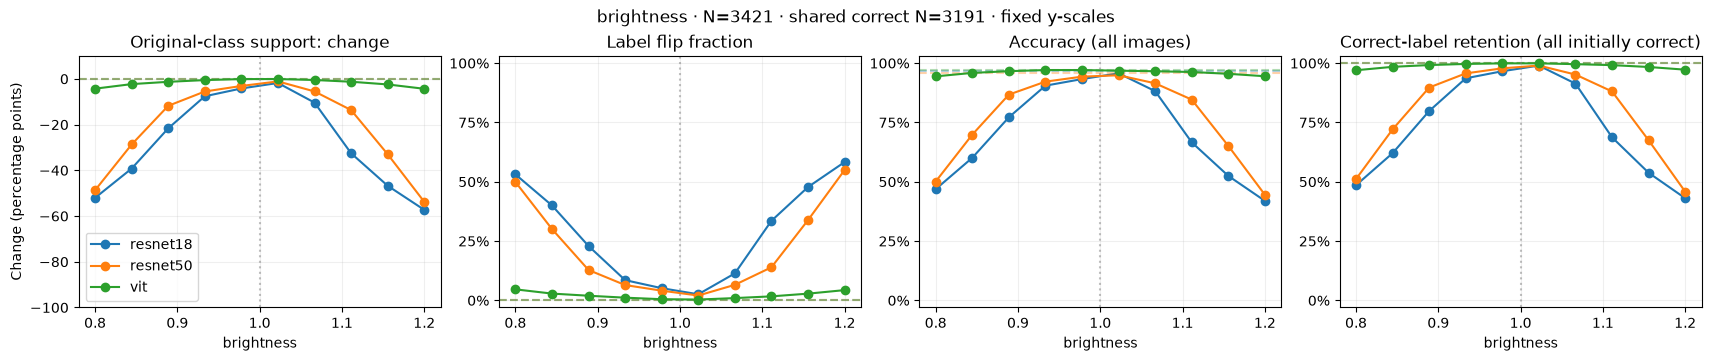

In [10]:
plot_stability('brightness', levels['brightness'])

Compare brightness accuracy curves across models and then check whether their class-specific responses are uniform. Mean accuracy is 71.3% for ResNet18, 77.4% for ResNet50 and 96.1% for ViT, with especially large CNN support losses for monocytes in the class map. The CNNs therefore depend strongly on appearance changes that do not displace image structures, and that dependence differs between cell classes.

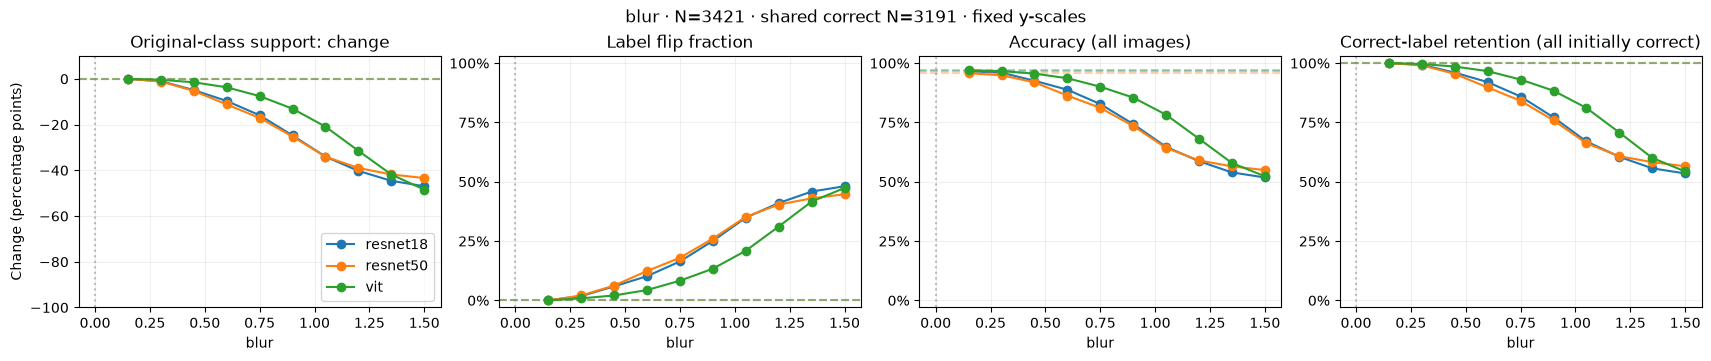

In [11]:
plot_stability('blur', levels['blur'])

Compare model rankings at moderate blur with their accuracy at the strongest blur level. At radius 1.5, ViT accuracy is 52.3%, versus 51.8% and 54.9% for the CNNs, despite its advantage at moderate levels. ViT’s tolerance to other interventions therefore does not imply tolerance to strong removal of spatial detail.

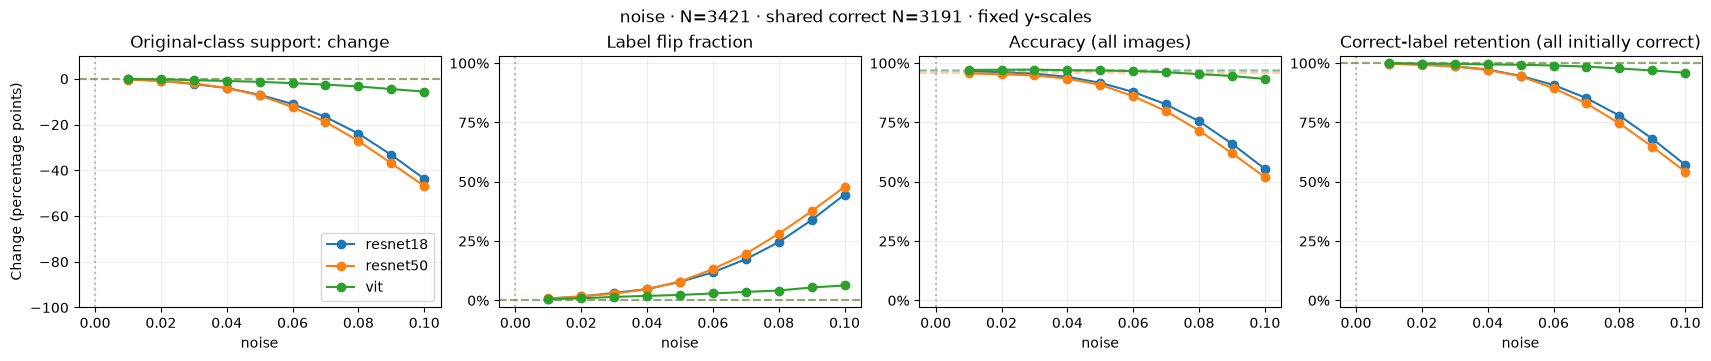

In [12]:
plot_stability('noise', levels['noise'])

Compare noise accuracy curves with the blur curves, averaging the three noise realizations within each image. At noise σ=0.1, accuracy is 55.4% for ResNet18, 52.0% for ResNet50 and 93.3% for ViT. ViT therefore tolerates added random variation much better than the CNNs, but its strong-blur failures show that this advantage does not extend equally to systematic smoothing.

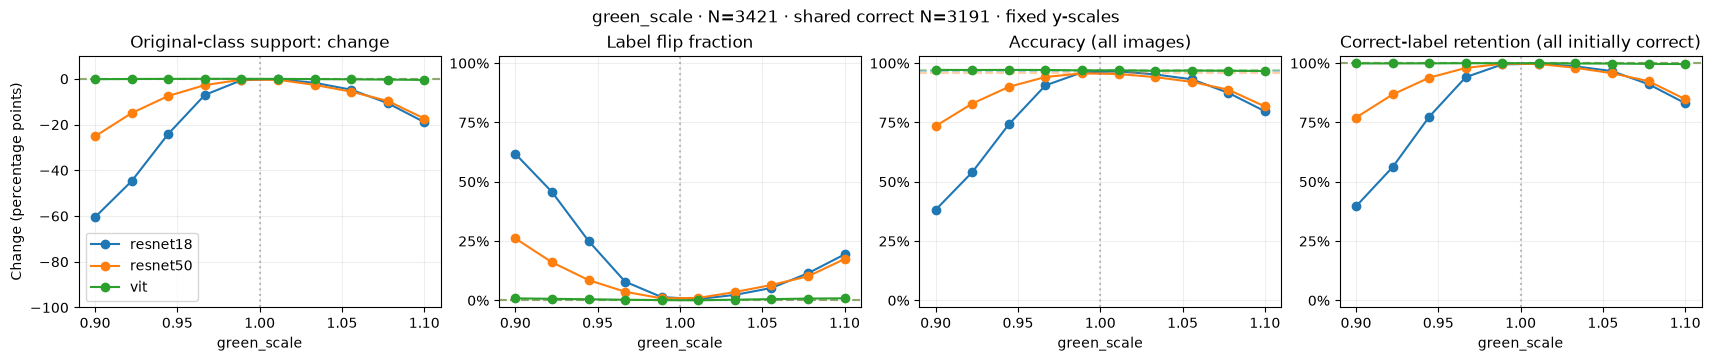

In [13]:
plot_stability('green_scale', levels['green_scale'])

Compare green scaling below and above one to check whether equal-sized changes have symmetric effects. ResNet18 accuracy is 38.2% at factor 0.9 but 79.7% at 1.1, with a weaker blue-channel response and a different ResNet50 profile. The failures therefore depend on the direction and channel of the color change, not simply its distance from the original input.

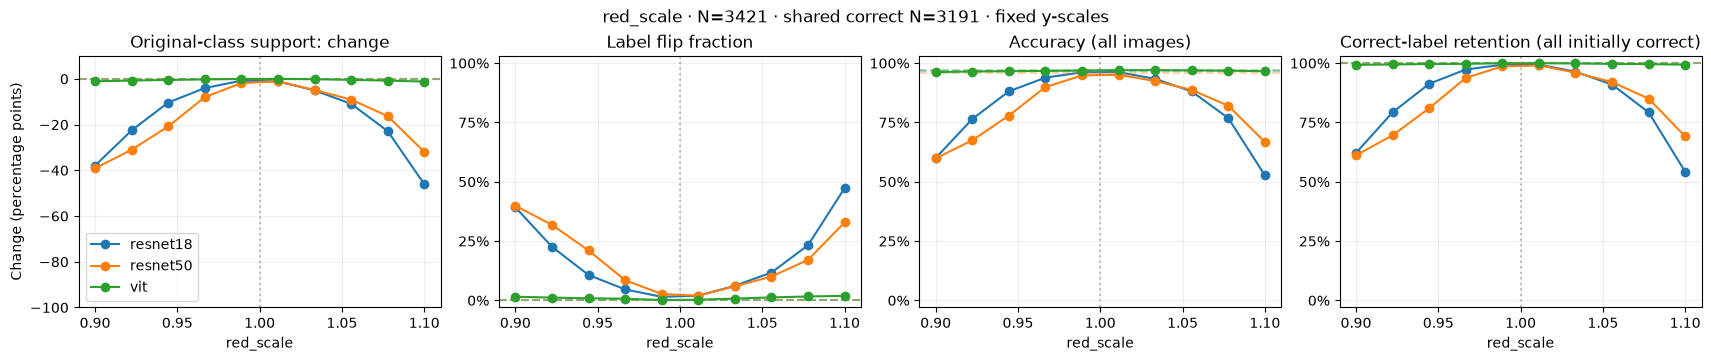

In [14]:
plot_stability('red_scale', levels['red_scale'])

Compare red-scaling label flips across models and contrast their ranking with rotation and green scaling. Red scaling changes 16.9% of ResNet18 and 17.2% of ResNet50 decisions, versus only 1.0% of ViT decisions. The CNNs are similarly sensitive here despite their different responses elsewhere, so one overall robustness ranking would hide intervention-specific weaknesses.

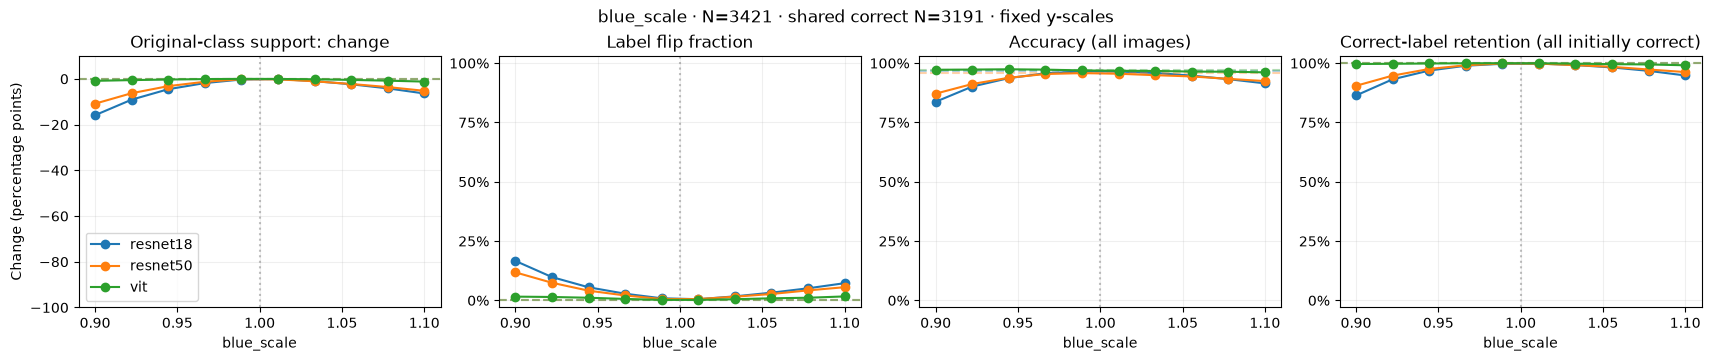

In [15]:
plot_stability('blue_scale', levels['blue_scale'])

Compare blue-channel label flips with red and green scaling over the same factor interval. Blue scaling changes only 5.3% of ResNet18 and 4.1% of ResNet50 decisions, below their red and green responses. The color sensitivity is therefore channel-specific, although raw RGB gains are not independently controlled staining components.

## Conditional correctness transitions — normalize by the initially correct or initially wrong group; average noise repeats within images

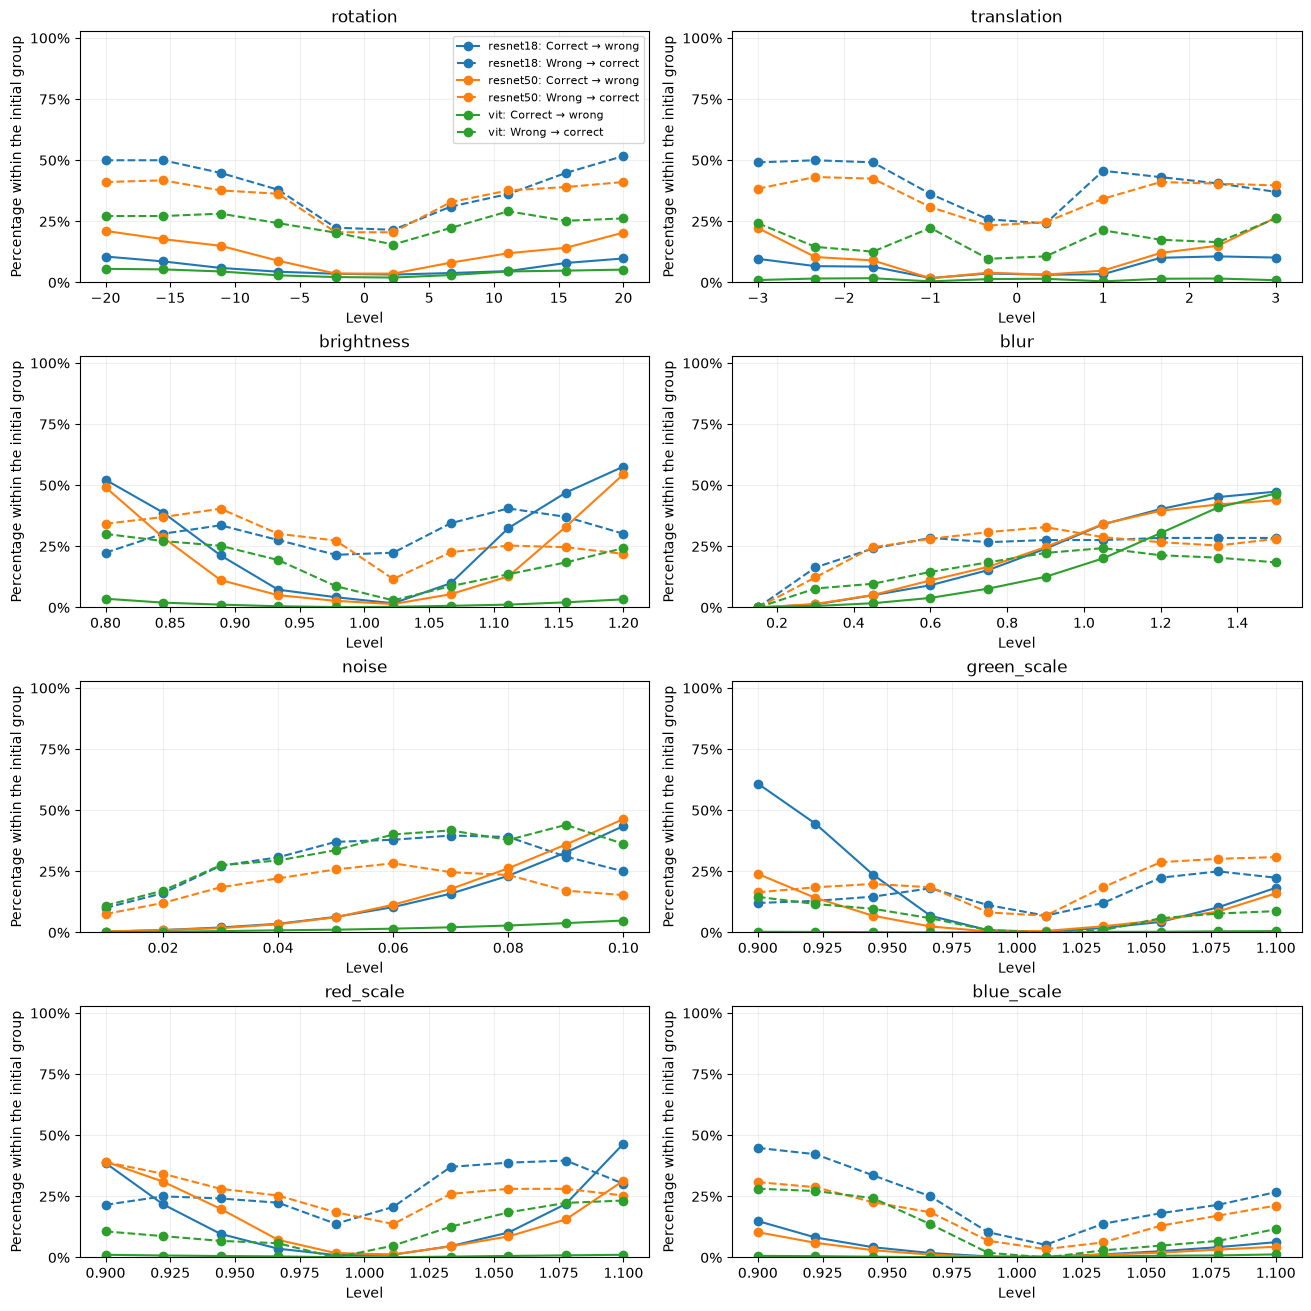

In [16]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13), layout='constrained')
for ax, (kind, values) in zip(axes.flat, levels.items()):
    for m, name in enumerate(model_names):
        for title, style in [('Correct → wrong', '-'), ('Wrong → correct', '--')]:
            initial_accuracy = (base_class[m] == labels).mean()
            denominator = initial_accuracy if title == 'Correct → wrong' else 1 - initial_accuracy
            rate = metrics[kind][title][m].mean(-1) / denominator if denominator else np.full(len(values), np.nan)
            ax.plot(values, rate, style,
                    color=f'C{m}', marker='o', label=f'{name}: {title}')
    ax.set(title=kind, xlabel='Level', ylabel='Percentage within the initial group',
           ylim=(0, 1.03), yticks=np.linspace(0, 1, 5))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.show()

Compare solid correct-to-wrong curves with dashed wrong-to-correct curves, each normalized by its own initial group. Averaged across rotation levels, ResNet18 becomes wrong on 6.3% of its 3,305 initially correct images and correct on 39.1% of its 116 initial errors. These view-dependent reversals reveal decision instability, not necessarily lower confidence, and rotation still reduces overall accuracy because losses in the larger correct group outweigh gains in the error group.

## 2B — Transformation sensitivity by true class: mean change in support for the original prediction; equal weight per level

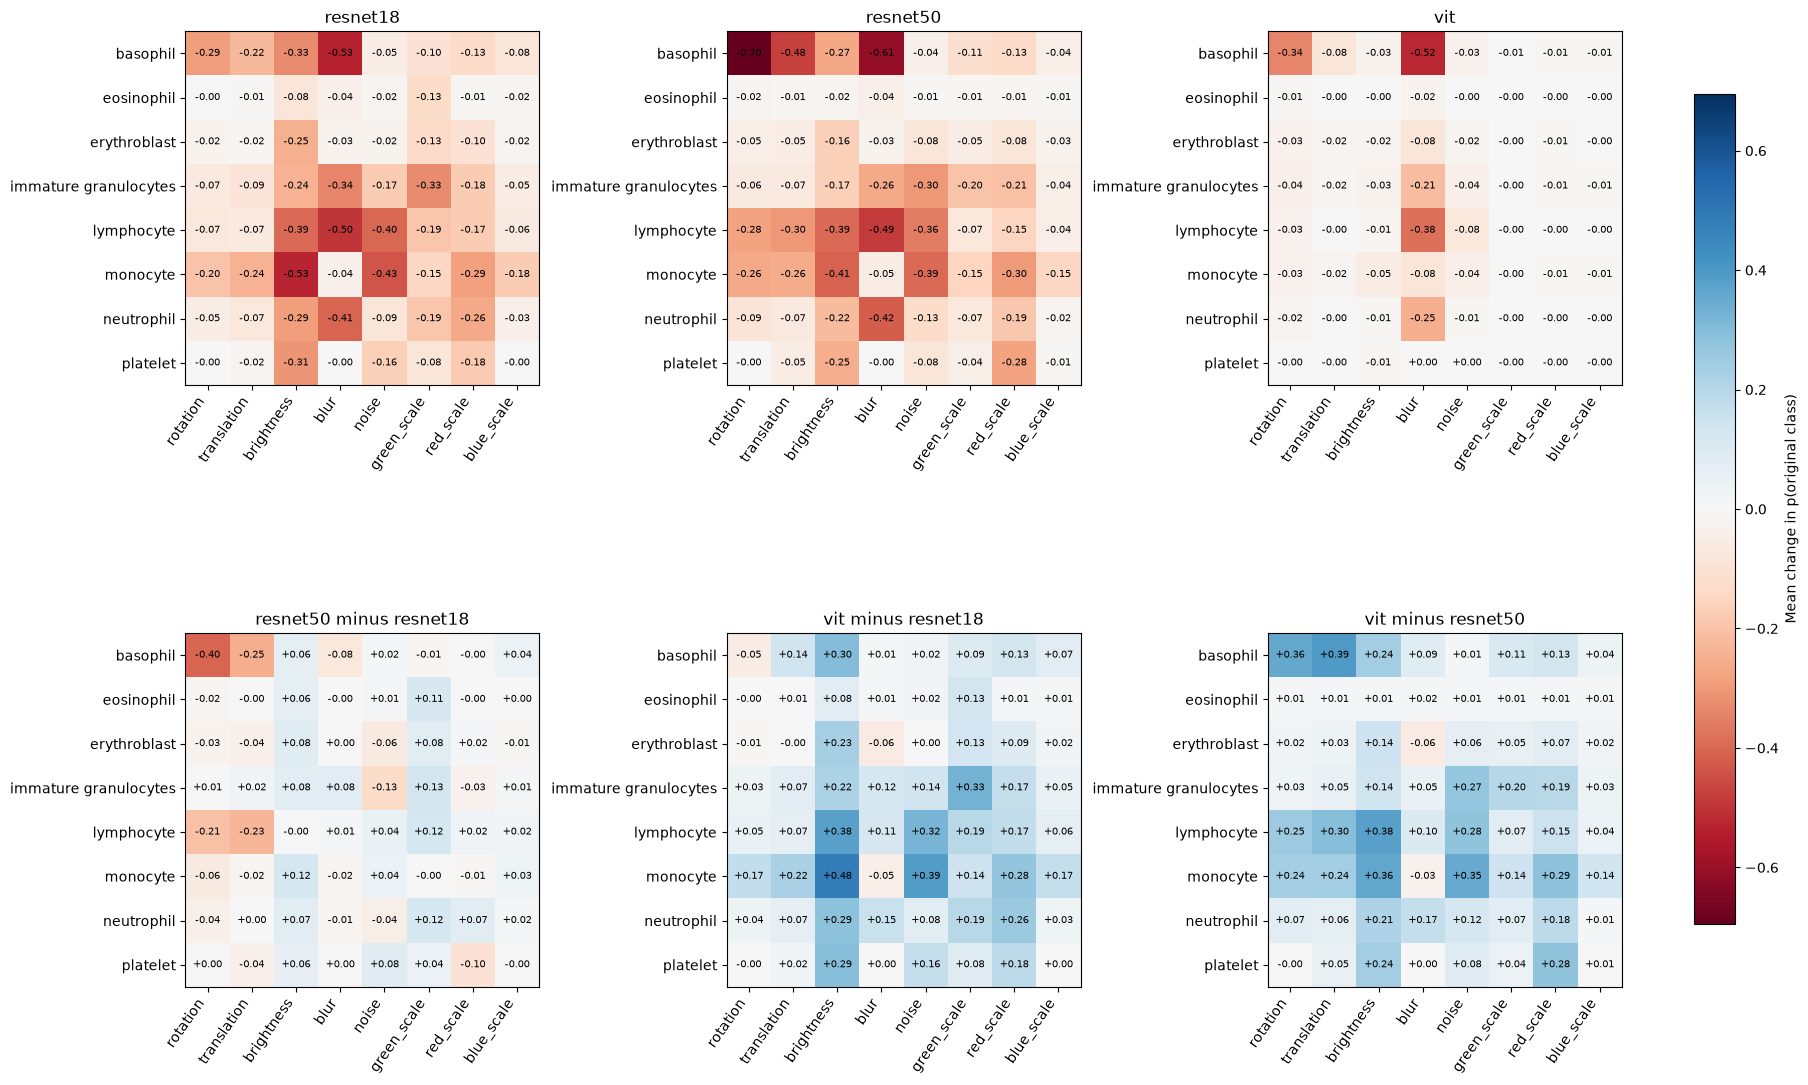

In [17]:
fingerprints = np.stack([np.array([
    metrics[kind]['Change in p(original class)'][m][:, labels == c].mean()
    for c in range(8) for kind in levels]).reshape(8, 8) for m in range(len(model_names))])
matrices = [*fingerprints, *[fingerprints[j] - fingerprints[i] for i, j in pairs]]
titles = [*model_names, *[f'{model_names[j]} minus {model_names[i]}' for i, j in pairs]]
scale = max(np.abs(matrices).max(), 0.01)
fig, axes = plt.subplots(2, 3, figsize=(18, 12), layout='constrained')
for ax, matrix, title in zip(axes.flat, matrices, titles):
    im = ax.imshow(matrix, cmap='RdBu', vmin=-scale, vmax=scale)
    ax.set(title=title, xticks=range(8), xticklabels=list(levels), yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=55, ha='right')
    for c in range(8):
        for j in range(8):
            ax.text(j, c, f'{matrix[c, j]:+.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.7, label='Mean change in p(original class)')
plt.show()


In model maps, red/blue means loss/gain of original-class support and near zero means little change; in first-model-minus-second-model maps, blue means a more positive change for the first model, usually less loss. ViT minus ResNet50 is positive in 61 of 64 class/transformation cells, whereas ResNet50 minus ResNet18 is −0.40 for basophils under rotation. ViT therefore usually retains original-class support better relative to ResNet50, but blue is not proof of accuracy or unchanged labels because each model tracks its own potentially wrong original prediction.

## 2C — Selected examples of translation, brightness and blur; one largest-drop image per operation, not representative samples

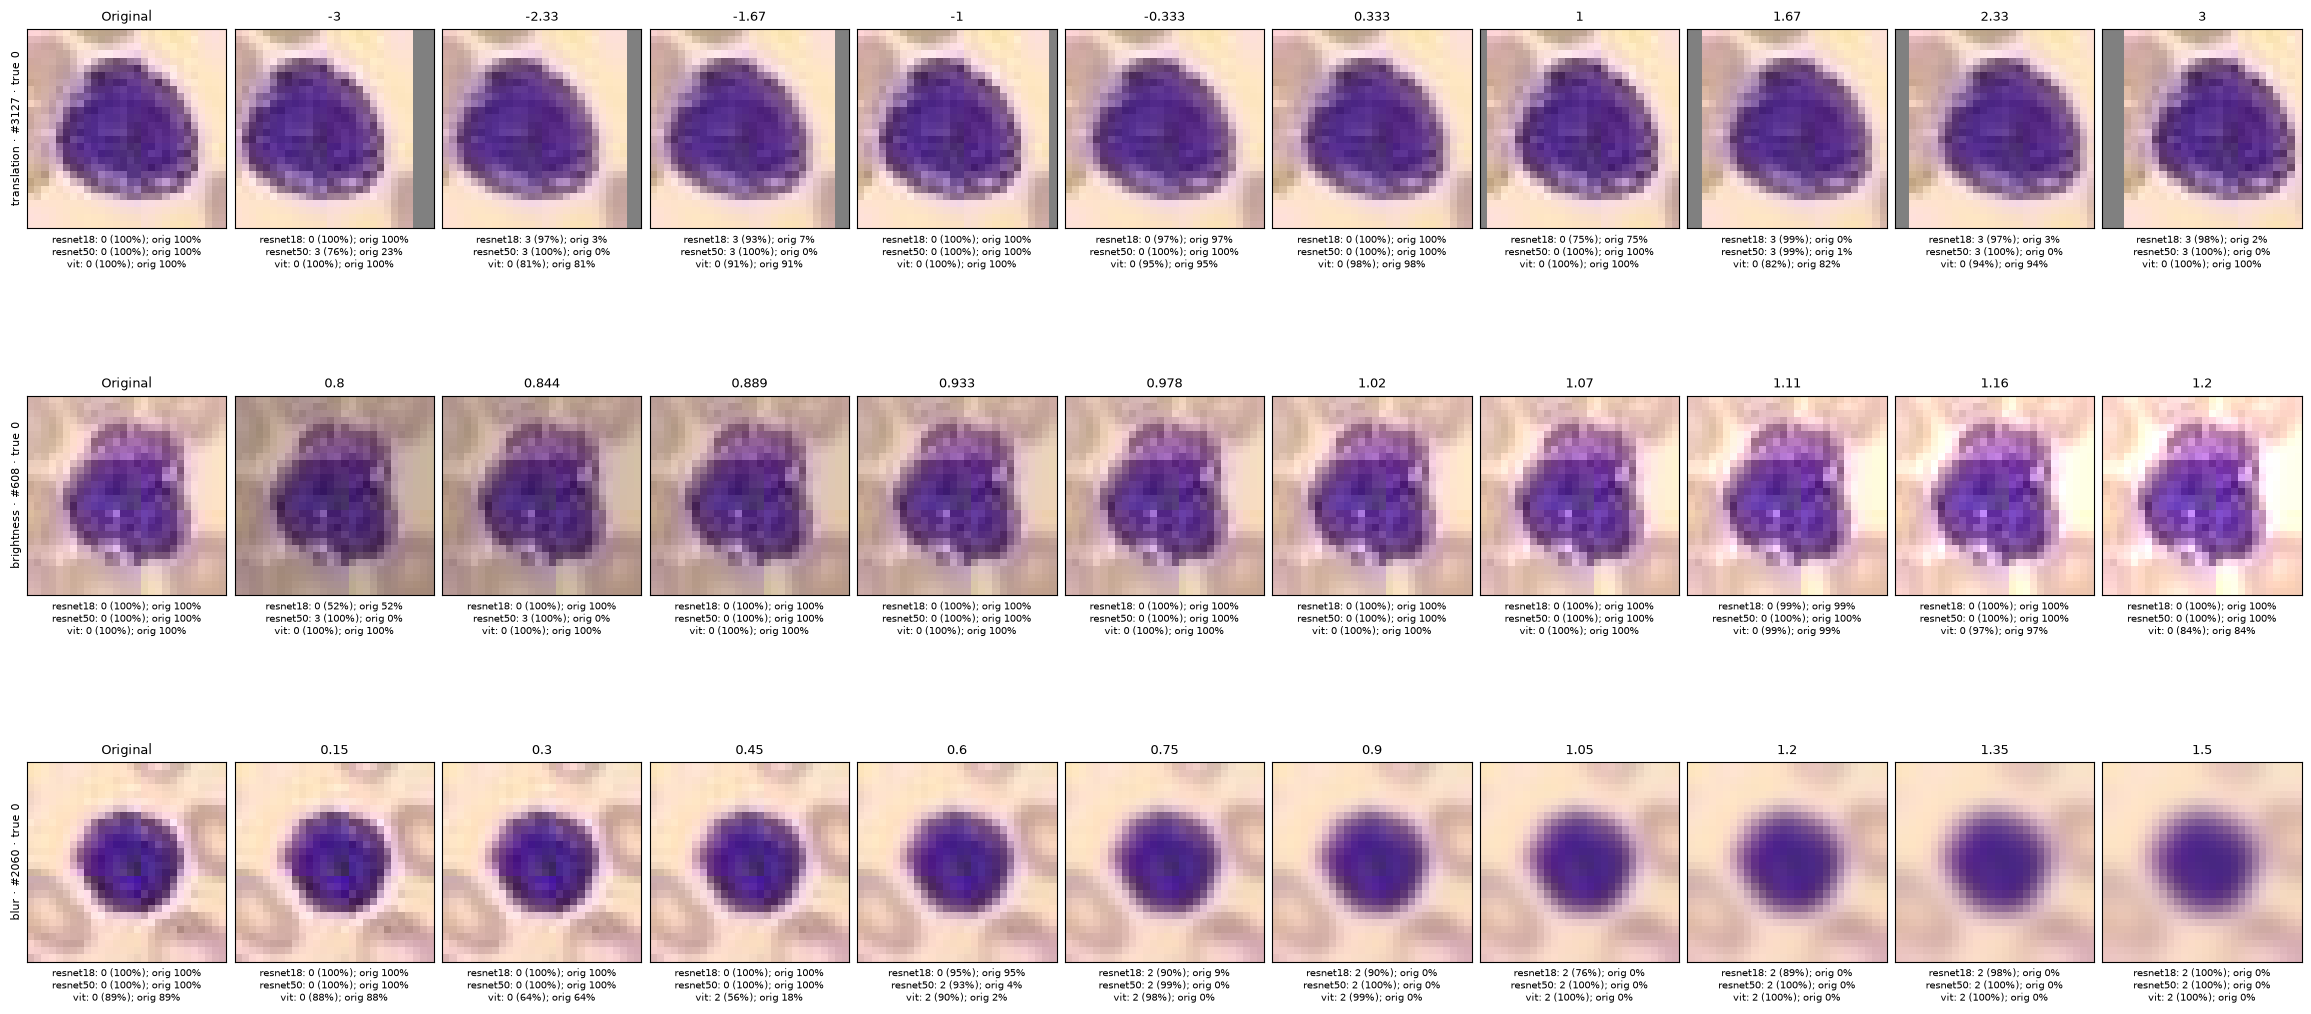

In [18]:
cases = ['translation', 'brightness', 'blur']
fig, axes = plt.subplots(len(cases), 11, figsize=(23, 11), layout='constrained')
for row, kind in enumerate(cases):
    values = levels[kind]
    p0 = np.take_along_axis(probabilities[kind][:, :, 0], base_class[:, None, :, None], axis=-1)[..., 0]
    pos = (base_probability[:, None, :] - p0).max(axis=(0, 1)).argmax()
    for col in range(11):
        ax = axes[row, col]
        ax.imshow(images[pos] if col == 0 else transform(images[pos:pos + 1], kind, values[col - 1])[0])
        p = baseline[:, pos] if col == 0 else probabilities[kind][:, col - 1, 0, pos]
        details = [f'{name}: {p[m].argmax()} ({p[m].max():.0%}); orig {p[m, base_class[m, pos]]:.0%}'
                   for m, name in enumerate(model_names)]
        ax.set_title('Original' if col == 0 else f'{values[col - 1]:.3g}', fontsize=9)
        ax.set_xlabel('\n'.join(details), fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(f'{kind} · #{indices[pos]} · true {labels[pos]}', fontsize=8)
plt.show()

Follow each selected image’s class labels across transformation levels rather than looking only at the endpoints. For translation #3127, ResNet18 switches away from basophil and back before switching again, while blur #2060 sends all three models to erythroblast. These selected largest-drop cases illustrate non-monotonic and shared decision changes, not how frequently those patterns occur in the population.